# Task 1a: Data overview and examples across people and digits

**Owner:** account 1 (Lungelo-DS)

Checks the structure of `handwriting.rds`, then shows examples across writers and digits.
Session effects and limitations are explored in `02_eda_sessions_and_limitations.ipynb`.

In [1]:
import sys
sys.path.append("../src")  # so the notebook can import our own modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_utils import load_handwriting, select
from eda_plots import show_grid, show_mean_images, image_features

images, meta = load_handwriting()  # pixels scaled to [0, 1]

## 1. Structure and balance

In [2]:
print("images:", images.shape, images.dtype,
      "| pixel range:", images.min(), "to", images.max())
print("metadata:", meta.shape, "| missing values:", meta.isna().sum().sum())
meta.head()

images: (25000, 28, 28) float32 | pixel range: 0.0 to 1.0
metadata: (25000, 5) | missing values: 0


,image_id,person_id,digit,session,replicate
0,1,1,0,1,1
1,2,1,0,1,2
2,3,1,0,1,3
3,4,1,0,1,4
4,5,1,0,1,5


In [3]:
# Every person x digit x session combination should have exactly 50 replicates.
counts = meta.groupby(["person_id", "digit", "session"]).size()
print("combinations:", len(counts), "| images per combination:", counts.unique())
print("writers:", meta.person_id.nunique(), "| digits:", sorted(meta.digit.unique()),
      "| sessions:", sorted(meta.session.unique()))

combinations: 500 | images per combination: [50]
writers: 20 | digits: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | sessions: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


share of pixels that are exactly 0 (background): 0.847
share of pixels above 0.5 (clear ink):           0.086


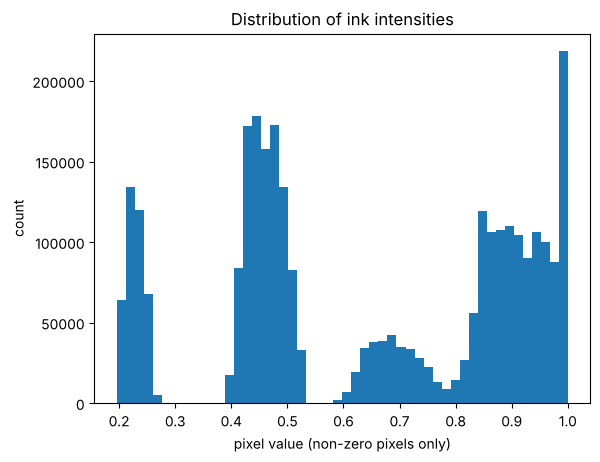

In [4]:
# How much of each image is ink?
print("share of pixels that are exactly 0 (background):", round((images == 0).mean(), 3))
print("share of pixels above 0.5 (clear ink):          ", round((images > 0.5).mean(), 3))

plt.hist(images[images > 0].ravel(), bins=50)
plt.xlabel("pixel value (non-zero pixels only)")
plt.ylabel("count")
plt.title("Distribution of ink intensities")
plt.show()

## 2. Examples across people and digits (session 1, replicate 1)

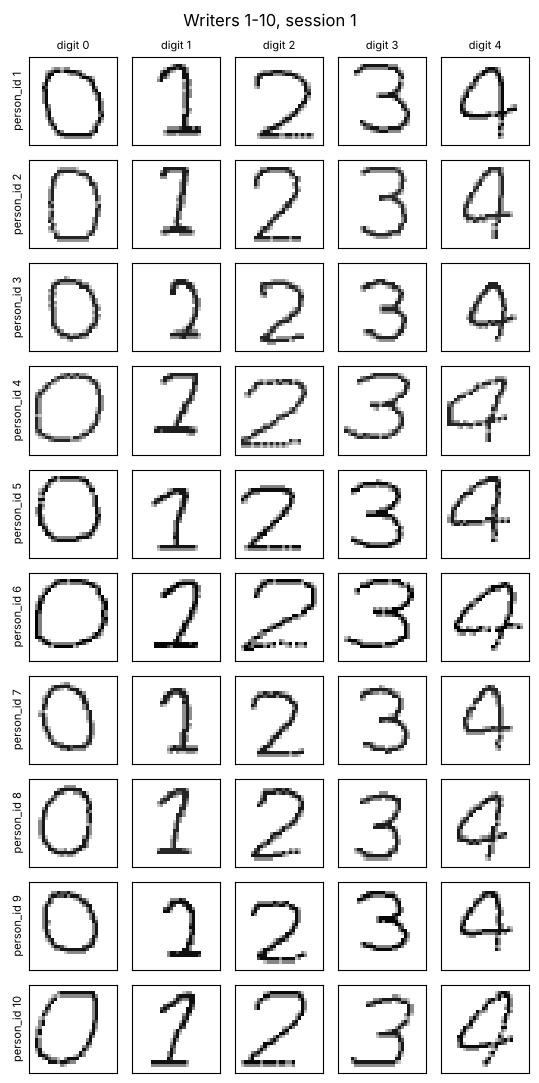

In [5]:
fig = show_grid(images, meta, row_var="person_id", col_var="digit",
                row_values=range(1, 11), col_values=range(5),
                fixed={"session": 1}, title="Writers 1-10, session 1")
plt.show()

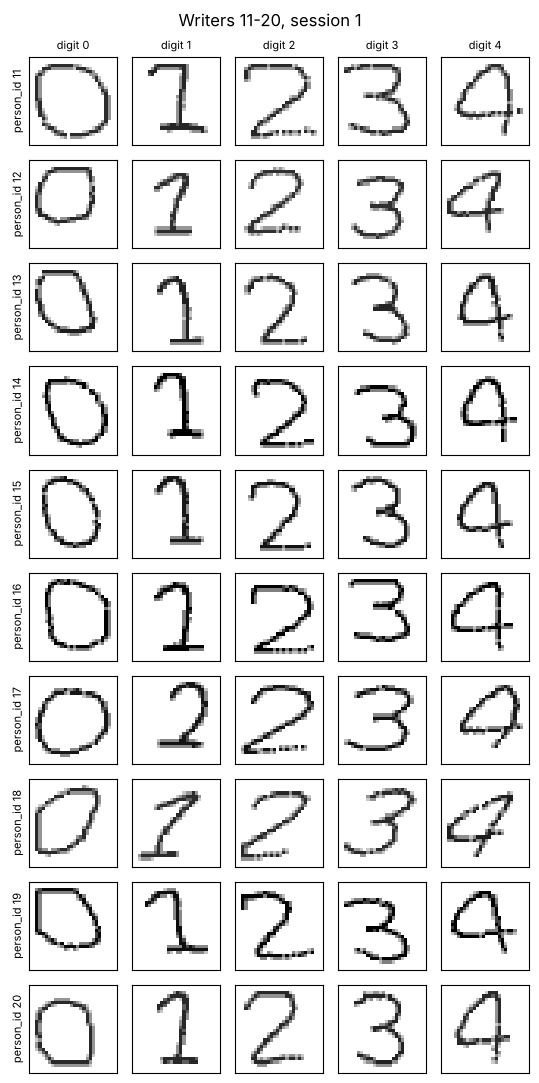

In [6]:
fig = show_grid(images, meta, row_var="person_id", col_var="digit",
                row_values=range(11, 21), col_values=range(5),
                fixed={"session": 1}, title="Writers 11-20, session 1")
plt.show()

## 3. Average image per writer and digit

Each cell averages all 250 images (5 sessions x 50 replicates) for that writer and digit.
A sharp average means the writer is consistent; a blurry one means their digits move around.

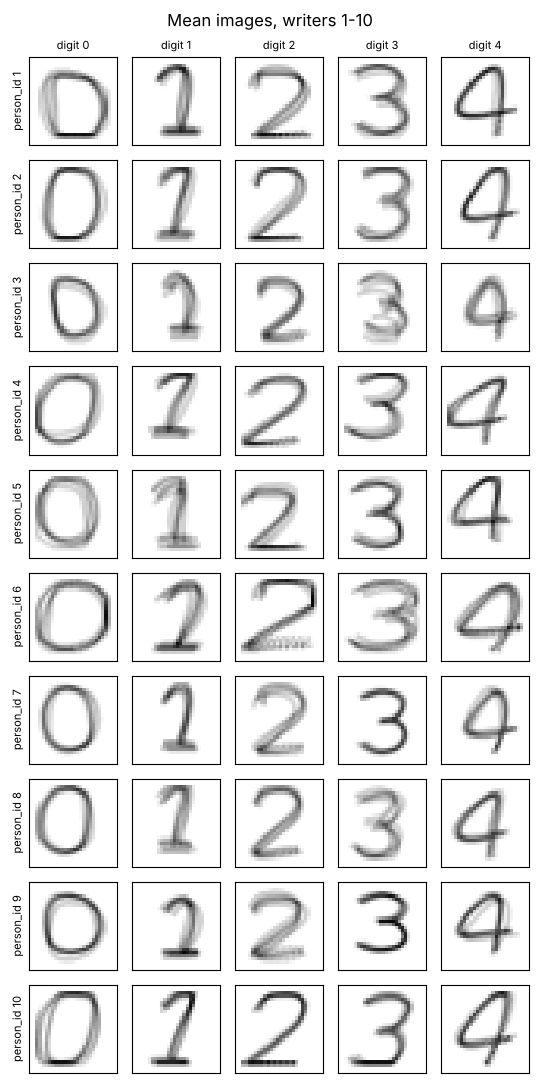

In [7]:
fig = show_mean_images(images, meta, row_var="person_id", col_var="digit",
                       row_values=range(1, 11), col_values=range(5),
                       title="Mean images, writers 1-10")
plt.show()

## 4. Simple style measurements by digit

In [8]:
features = pd.concat([meta, pd.DataFrame(image_features(images))], axis=1)
features.groupby("digit")[["ink", "width", "height", "slant"]].mean().round(2)

,ink,width,height,slant
digit,,,,
0,84.699997,19.12,21.13,-0.01
1,66.650002,13.48,20.69,-0.02
2,79.870003,18.50,21.30,0.11
3,77.690002,17.57,20.75,0.01
4,77.300003,17.52,19.62,0.11


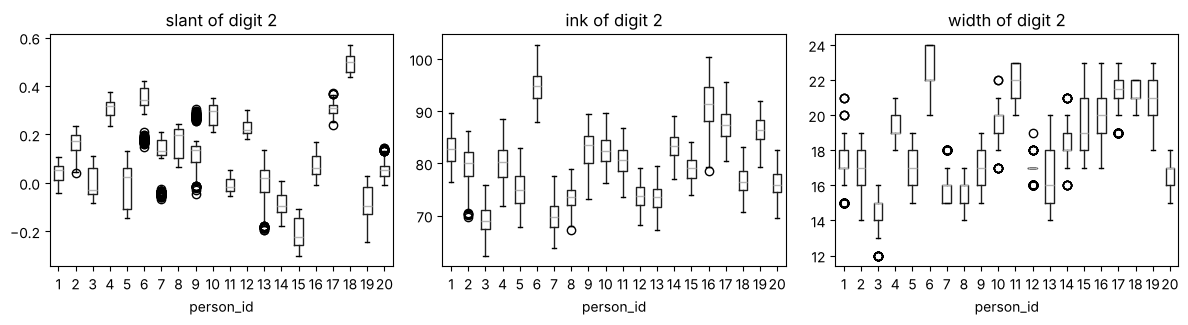

In [9]:
# How much do writers differ on each measurement, for one digit?
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
digit2 = features[features.digit == 2]
for ax, col in zip(axes, ["slant", "ink", "width"]):
    digit2.boxplot(column=col, by="person_id", ax=ax, grid=False)
    ax.set_title(f"{col} of digit 2")
    ax.set_xlabel("person_id")
plt.suptitle("")
plt.tight_layout()
plt.show()

## Notes for the report

Write your own observations here, for example: which digits look most different between writers,
and what styles you can see (slant, size, stroke thickness, open/closed loops).